In [ ]:

import pandas as pd

#carga archivos
df_age = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/Age_at_visit_29Sep2026.csv')
df_demo = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/Demographics_29Sep2026.csv')
df_family = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/Family_History_29Sep2026.csv')
df_genetics = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/iu_genetic_consensus_20251025_29Sep2026.csv')
df_updrs = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/MDS-UPDRS_Part_III_29Sep2026.csv')
df_bio = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/Current_Biospecimen_Analysis_Results_29Sep2026.csv')


df_bio = df_bio.rename(columns={'CLINICAL_EVENT': 'EVENT_ID'})

df_nfl = df_bio[df_bio['TESTNAME'].astype(str).str.contains('NfL|Neurofilament', case=False, na=False)]


cols_a_borrar = ['EVENT_ID', 'PAG_NAME', 'INFODT', 'ORIG_ENTRY', 'LAST_UPDATE']

df_demo_static = df_demo.drop_duplicates(subset=['PATNO']).drop(columns=cols_a_borrar, errors='ignore')
df_family_static = df_family.drop_duplicates(subset=['PATNO']).drop(columns=cols_a_borrar, errors='ignore')
df_genetics_static = df_genetics.drop_duplicates(subset=['PATNO'])


df_static = pd.merge(df_demo_static, df_genetics_static, on='PATNO', how='inner')
df_static = pd.merge(df_static, df_family_static, on='PATNO', how='left')

df_longitudinal = pd.merge(df_age[['PATNO', 'EVENT_ID', 'AGE_AT_VISIT']],
                           df_updrs[['PATNO', 'EVENT_ID', 'NP3TOT']],
                           on=['PATNO', 'EVENT_ID'], how='inner')

df_longitudinal = pd.merge(df_longitudinal,
                           df_nfl[['PATNO', 'EVENT_ID', 'TESTVALUE']],
                           on=['PATNO', 'EVENT_ID'], how='inner')

df_final = pd.merge(df_static, df_longitudinal, on='PATNO', how='inner')

#construír dataset
columnas_modelo = ['PATNO', 'EVENT_ID', 'AGE_AT_VISIT', 'SEX', 'APOE', 'GBA', 'NP3TOT', 'TESTVALUE']
df_modelo = df_final[columnas_modelo].copy()


df_modelo = df_modelo.rename(columns={'NP3TOT': 'MDS_UPDRS_III', 'TESTVALUE': 'NFL_SERUM'})
df_modelo = df_modelo.dropna()



C:\Users\ricvi\AppData\Local\Temp\ipykernel_13096\3126304393.py:8: DtypeWarning: Columns (16,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df_updrs = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/MDS-UPDRS_Part_III_29Sep2026.csv')
C:\Users\ricvi\AppData\Local\Temp\ipykernel_13096\3126304393.py:9: DtypeWarning: Columns (6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df_bio = pd.read_csv('C:/Users/ricvi/Documents/san_pablo_ceu/curso_2627/proyectsii/data/Current_Biospecimen_Analysis_Results_29Sep2026.csv')


In [2]:

df_modelo['APOE_E4'] = df_modelo['APOE'].str.contains('E4').astype(float)
df_modelo = df_modelo.drop(columns=['APOE'])

In [3]:
print(f"Dataset final listo. Total de visitas registradas con datos completos: {len(df_modelo)}")
print(df_modelo.head())

Dataset final listo. Total de visitas registradas con datos completos: 13120
   PATNO EVENT_ID  AGE_AT_VISIT  SEX GBA  MDS_UPDRS_III NFL_SERUM  APOE_E4
0   3000       BL          69.1  0.0   0            4.0      16.4      0.0
1   3000      V04          70.2  0.0   0            1.0      16.7      0.0
2   3000      V06          71.2  0.0   0            4.0      20.5      0.0
3   3000      V08          72.3  0.0   0            2.0      21.7      0.0
4   3000      V12          74.3  0.0   0            3.0      17.8      0.0


In [ ]:
import pandas as pd
import numpy as np

#eliminar datos en formato incorrecto y nans
df_modelo['NFL_SERUM'] = pd.to_numeric(df_modelo['NFL_SERUM'], errors='coerce')
df_modelo['GBA'] = pd.to_numeric(df_modelo['GBA'], errors='coerce')
df_modelo = df_modelo.dropna(subset=['NFL_SERUM'])

df_modelo = df_modelo.sort_values(by=['PATNO', 'AGE_AT_VISIT'])
df_basal = df_modelo.groupby('PATNO').first().reset_index()

# Extraemos solo lo que necesitamos
df_basal = df_basal[['PATNO', 'AGE_AT_VISIT', 'NFL_SERUM']]
df_basal = df_basal.rename(columns={'AGE_AT_VISIT': 'AGE_BASELINE', 'NFL_SERUM': 'NFL_BASELINE'})

df_pm = pd.merge(df_modelo, df_basal, on='PATNO', how='left')

df_pm['TIME_YEARS'] = df_pm['AGE_AT_VISIT'] - df_pm['AGE_BASELINE']

df_pm['LOG2_NFL_BASELINE'] = np.log2(df_pm['NFL_BASELINE'])

df_pm = df_pm.dropna() # limpieza final

patient_idx, unique_patients = pd.factorize(df_pm['PATNO'])
n_patients = len(unique_patients)

time_val = df_pm['TIME_YEARS'].values
age_val = df_pm['AGE_BASELINE'].values - df_pm['AGE_BASELINE'].mean() # Edad centrada
sex_val = df_pm['SEX'].values
nfl_val = df_pm['LOG2_NFL_BASELINE'].values - df_pm['LOG2_NFL_BASELINE'].mean() # NfL centrado
y_obs = df_pm['MDS_UPDRS_III'].values

print("Vectores listos. Pacientes únicos:", n_patients)
print("Total de observaciones válidas:", len(y_obs))

Vectores listos. Pacientes únicos: 1646
Total de observaciones válidas: 11886


In [ ]:
import pymc as pm
import arviz as az

with pm.Model() as model_real:

    beta_0 = pm.Normal('beta_0', mu=20.0, sigma=10.0)
    beta_1 = pm.Normal('beta_1', mu=0.0, sigma=5.0)
    beta_2 = pm.Normal('beta_2', mu=0.0, sigma=5.0)
    beta_3 = pm.Normal('beta_3', mu=0.0, sigma=5.0)
    beta_4 = pm.Normal('beta_4', mu=0.0, sigma=5.0)
    beta_5 = pm.Normal('beta_5', mu=0.0, sigma=5.0) 


    sd_dist = pm.Exponential.dist(1.0, shape=2)
    chol, corr, stds = pm.LKJCholeskyCov(
        'chol', n=2, eta=2.0, sd_dist=sd_dist, compute_corr=True
    )

    z = pm.Normal('z', mu=0.0, sigma=1.0, shape=(2, n_patients))
    u = pm.Deterministic('u', chol @ z)
    u_0 = u[0, patient_idx]
    u_1 = u[1, patient_idx]

    mu = (beta_0 + u_0) + \
         (beta_1 + u_1) * time_val + \
         beta_2 * age_val + \
         beta_3 * sex_val + \
         beta_4 * nfl_val + \
         beta_5 * (time_val * nfl_val)

    sigma = pm.Exponential('sigma_obs', 1.0)
    y = pm.Normal('y', mu=mu, sigma=sigma, observed=y_obs)

    print("Iniciando MCMC (NUTS) con datos reales PPMI...")
    trace_real = pm.sample(
        draws=2000,
        tune=1500,
        chains=4,
        cores=4,
        target_accept=0.95,
        return_inferencedata=True,
        random_seed=42
    )

# convergencia
summary_real = az.summary(trace_real, var_names=["beta_0", "beta_1", "beta_2", "beta_3", "beta_4", "beta_5"])
print("\n--- Diagnósticos MCMC ---")
print(summary_real)

g++ not available, if using conda: `conda install gxx`


Iniciando MCMC (NUTS) con datos reales PPMI...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta_0, beta_1, beta_2, beta_3, beta_4, beta_5, chol, z, sigma_obs]


C:\Users\ricvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\
Python313\site-packages\rich\live.py:256: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 160 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details



--- Diagnósticos MCMC ---
          mean     sd eti89_lb eti89_ub  ess_bulk  ess_tail r_hat mcse_mean  \
beta_0   10.78   0.44       10       11       640      1174  1.01     0.017   
beta_1   1.136  0.093     0.99      1.3      1141      2143  1.00    0.0027   
beta_2  -0.066  0.039    -0.13   -0.005       373       863  1.01     0.002   
beta_3    1.67   0.57     0.76      2.6       619      1062  1.00     0.023   
beta_4    1.32   0.48     0.55      2.1       480       852  1.01     0.022   
beta_5   0.308  0.107     0.14     0.48      1147      1955  1.00    0.0032   

       mcse_sd  
beta_0   0.012  
beta_1  0.0019  
beta_2  0.0015  
beta_3   0.015  
beta_4   0.016  
beta_5  0.0023  


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


b5_samples = trace_real.posterior["beta_5"].values.flatten()
media_b5 = np.mean(b5_samples)
hdi_2_5 = np.percentile(b5_samples, 2.5)
hdi_97_5 = np.percentile(b5_samples, 97.5)

print(f"\nMedia posterior de beta_5 (Datos Reales): {media_b5:.3f}")
print(f"Intervalo de Credibilidad 95%: [{hdi_2_5:.3f}, {hdi_97_5:.3f}]")

plt.figure(figsize=(9, 5))
plt.hist(b5_samples, bins=50, density=True, alpha=0.7, color='#2ecc71', edgecolor='black')

plt.axvline(x=0.0, color='red', linestyle='--', linewidth=2, label='Referencia Nula (0.0)')
plt.axvline(x=media_b5, color='darkgreen', linewidth=2, label=f'Media: {media_b5:.2f}')
plt.axvspan(hdi_2_5, hdi_97_5, color='#f1c40f', alpha=0.3, label='95% HDI')

plt.title('Distribución Posterior de $\\beta_5$ (Cohorte PPMI Real)', fontsize=13)
plt.xlabel('Valor de $\\beta_5$ (Aceleración de UPDRS III por Log2-NfL)', fontsize=11)
plt.ylabel('Densidad', fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('beta5_posterior_real.png', dpi=300)
plt.show()

<>:93: SyntaxWarning: invalid escape sequence '\m'
<>:93: SyntaxWarning: invalid escape sequence '\m'
C:\Users\ricvi\AppData\Local\Temp\ipykernel_13096\3156564644.py:93: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('Predicted MDS-UPDRS Part III ($\mu_{ij}$)', fontsize=11)


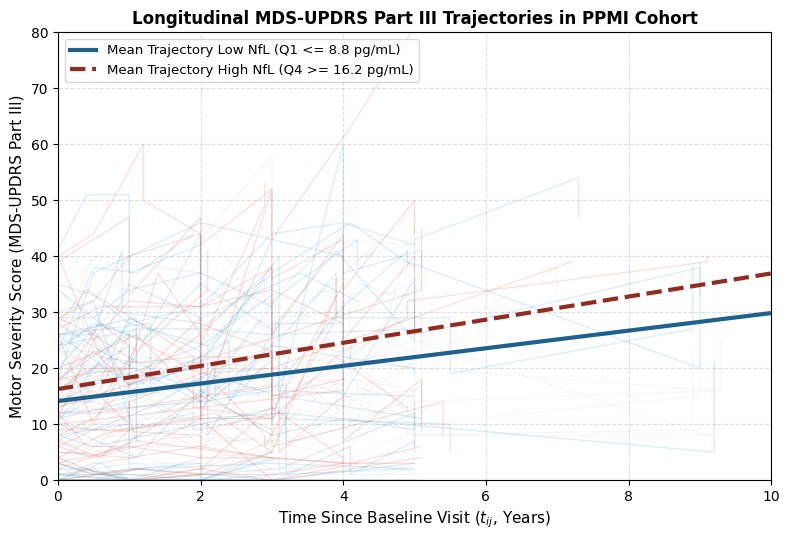

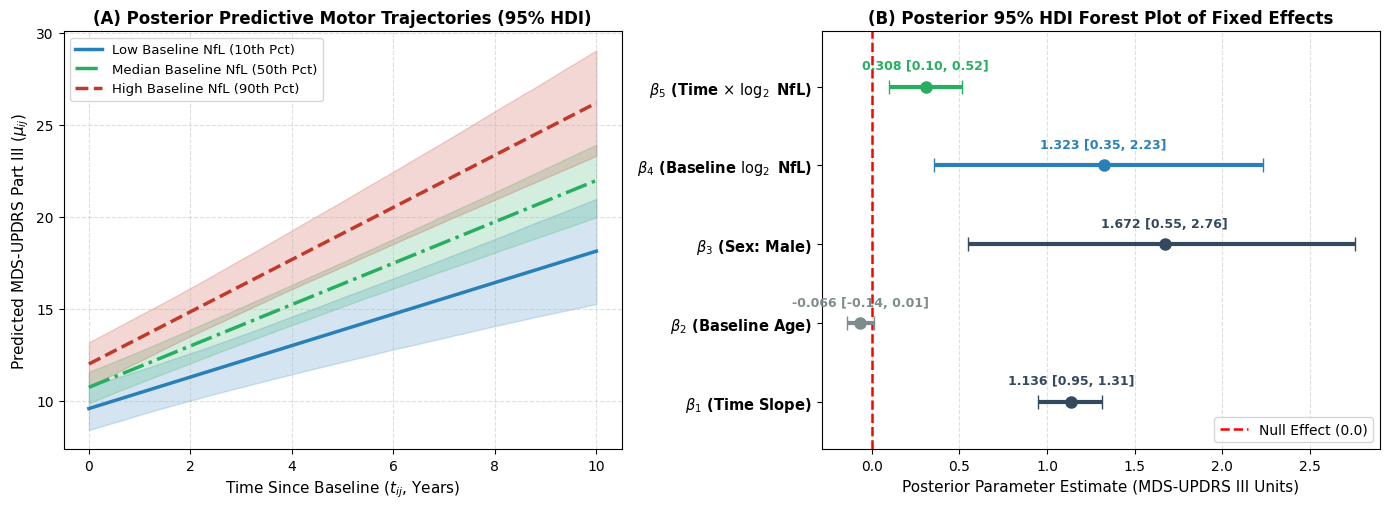

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


q25 = df_pm['NFL_BASELINE'].quantile(0.25)
q75 = df_pm['NFL_BASELINE'].quantile(0.75)

plt.figure(figsize=(8, 5.5))

np.random.seed(42)
pacientes_muestra = np.random.choice(df_pm['PATNO'].unique(), size=250, replace=False)
df_sample = df_pm[df_pm['PATNO'].isin(pacientes_muestra)]

for patno, group in df_sample.groupby('PATNO'):
    if len(group) >= 3:
        nfl_b = group['NFL_BASELINE'].iloc[0]
        if nfl_b >= q75:
            plt.plot(group['TIME_YEARS'], group['MDS_UPDRS_III'], color='#e74c3c', alpha=0.18, linewidth=0.9)
        elif nfl_b <= q25:
            plt.plot(group['TIME_YEARS'], group['MDS_UPDRS_III'], color='#3498db', alpha=0.18, linewidth=0.9)
        else:
            plt.plot(group['TIME_YEARS'], group['MDS_UPDRS_III'], color='gray', alpha=0.08, linewidth=0.7)

df_q1 = df_pm[df_pm['NFL_BASELINE'] <= q25]
df_q4 = df_pm[df_pm['NFL_BASELINE'] >= q75]

t_grid = np.linspace(0, 10, 100)
m_q1, b_q1 = np.polyfit(df_q1['TIME_YEARS'], df_q1['MDS_UPDRS_III'], 1)
m_q4, b_q4 = np.polyfit(df_q4['TIME_YEARS'], df_q4['MDS_UPDRS_III'], 1)

plt.plot(t_grid, m_q1 * t_grid + b_q1, color='#1f618d', linewidth=3,
         label=f'Mean Trajectory Low NfL (Q1 <= {q25:.1f} pg/mL)')
plt.plot(t_grid, m_q4 * t_grid + b_q4, color='#922b21', linewidth=3, linestyle='--',
         label=f'Mean Trajectory High NfL (Q4 >= {q75:.1f} pg/mL)')

plt.xlim(0, 10)
plt.ylim(0, 80)
plt.title('Longitudinal MDS-UPDRS Part III Trajectories in PPMI Cohort', fontsize=12, fontweight='bold')
plt.xlabel('Time Since Baseline Visit ($t_{ij}$, Years)', fontsize=11)
plt.ylabel('Motor Severity Score (MDS-UPDRS Part III)', fontsize=11)
plt.legend(loc='upper left', frameon=True, fontsize=9.5)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('spaghetti_plot_hito1_real.png', dpi=300)
plt.show()



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

b0_s = trace_real.posterior["beta_0"].values.flatten()
b1_s = trace_real.posterior["beta_1"].values.flatten()
b4_s = trace_real.posterior["beta_4"].values.flatten()
b5_s = trace_real.posterior["beta_5"].values.flatten()

p10_nfl = np.percentile(nfl_val, 10)
p50_nfl = np.percentile(nfl_val, 50)
p90_nfl = np.percentile(nfl_val, 90)

t_pred = np.linspace(0, 10, 50)

perfiles = [
    (p10_nfl, '#2980b9', 'Low Baseline NfL (10th Pct)', '-'),
    (p50_nfl, '#27ae60', 'Median Baseline NfL (50th Pct)', '-.'),
    (p90_nfl, '#c0392b', 'High Baseline NfL (90th Pct)', '--')
]

for nfl_lvl, color, label, ls in perfiles:

    mu_samples = (b0_s[:, None] + b4_s[:, None] * nfl_lvl) + \
                 (b1_s[:, None] + b5_s[:, None] * nfl_lvl) * t_pred[None, :]

    mu_mean = np.mean(mu_samples, axis=0)
    mu_low = np.percentile(mu_samples, 2.5, axis=0)
    mu_high = np.percentile(mu_samples, 97.5, axis=0)

    ax1.plot(t_pred, mu_mean, color=color, linewidth=2.5, linestyle=ls, label=label)
    ax1.fill_between(t_pred, mu_low, mu_high, color=color, alpha=0.2)

ax1.set_title('(A) Posterior Predictive Motor Trajectories (95% HDI)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Time Since Baseline ($t_{ij}$, Years)', fontsize=11)
ax1.set_ylabel('Predicted MDS-UPDRS Part III ($\mu_{ij}$)', fontsize=11)
ax1.legend(loc='upper left', frameon=True, fontsize=9.5)
ax1.grid(True, linestyle='--', alpha=0.4)

params = ['beta_1', 'beta_2', 'beta_3', 'beta_4', 'beta_5']
labels_p = [
    '$\\beta_1$ (Time Slope)',
    '$\\beta_2$ (Baseline Age)',
    '$\\beta_3$ (Sex: Male)',
    '$\\beta_4$ (Baseline $\\log_2$ NfL)',
    '$\\beta_5$ (Time $\\times$ $\\log_2$ NfL)'
]
colors_p = ['#34495e', '#7f8c8d', '#34495e', '#2980b9', '#27ae60']

y_pos = np.arange(len(params))
means, lows, highs = [], [], []

for p in params:
    s = trace_real.posterior[p].values.flatten()
    means.append(np.mean(s))
    lows.append(np.percentile(s, 2.5))
    highs.append(np.percentile(s, 97.5))

ax2.axvline(x=0.0, color='red', linestyle='--', linewidth=1.8, label='Null Effect (0.0)')

for i in range(len(params)):
    ax2.errorbar(means[i], y_pos[i], xerr=[[means[i] - lows[i]], [highs[i] - means[i]]],
                 fmt='o', color=colors_p[i], ecolor=colors_p[i], elinewidth=3, capsize=5, markersize=8)
    ax2.text(means[i], y_pos[i] + 0.22, f"{means[i]:.3f} [{lows[i]:.2f}, {highs[i]:.2f}]",
             ha='center', fontsize=9, fontweight='bold', color=colors_p[i])

ax2.set_yticks(y_pos)
ax2.set_yticklabels(labels_p, fontsize=10.5, fontweight='bold')
ax2.set_ylim(-0.6, len(params) - 0.3)
ax2.set_title('(B) Posterior 95% HDI Forest Plot of Fixed Effects', fontsize=12, fontweight='bold')
ax2.set_xlabel('Posterior Parameter Estimate (MDS-UPDRS III Units)', fontsize=11)
ax2.legend(loc='lower right', frameon=True)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('bayesian_stratification_panel.png', dpi=300)
plt.show()